
# Logistic Regression: Student Pass/Fail Prediction

## Objective
Build a machine-learning classification model that predicts
whether a student passes or fails based on available student
performance features.

## Target variable
- pass_fail

## Workflow
1. Load and explore the dataset.
2. Select input features and target.
3. Split data into training and testing sets.
4. Preprocess numerical and categorical features.
5. Train a logistic regression model.
6. Evaluate predictions using a confusion matrix and classification metrics.
7. Visualize the results.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

In [ ]:
df = pd.read_csv("../data/student_performance_5000.csv")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

df.head()

In [ ]:
print("Missing values:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df["pass_fail"].value_counts(dropna=False))

In [ ]:
target = "pass_fail"

candidate_features = [
    "study_hours",
    "attendance",
    "previous_grade",
    "assignments_completed",
    "age",
    "internet_access",
    "study_environment",
    "learning_style",
    "transport_mode"
]

features = [
    column for column in candidate_features
    if column in df.columns
]

if target not in df.columns:
    raise ValueError("The target column 'pass_fail' was not found.")

if not features:
    raise ValueError("No candidate input features were found.")

# Remove rows where the target is missing
df_model = df.dropna(subset=[target]).copy()

X = df_model[features].copy()
y = df_model[target].copy()

print("Selected features:", features)
print("Features not found:", [
    column for column in candidate_features
    if column not in df.columns
])

print("\nTarget classes:")
print(y.value_counts())

X.head()

In [ ]:
numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

In [ ]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created.")

In [ ]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Logistic regression model trained successfully.")

In [27]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
})

results.head(10)

,Actual,Predicted
0,Pass,Pass
1,Pass,Pass
2,Pass,Pass
3,Pass,Pass
4,Pass,Pass
5,Pass,Pass
6,Pass,Pass
7,Pass,Pass
8,Pass,Pass
9,Pass,Pass


In [25]:
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, pos_label='Pass', zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, pos_label='Pass', zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, pos_label='Pass', zero_division=0):.4f}")

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy:  0.9800
Precision: 0.9800
Recall:    1.0000
F1-score:  0.9899

Classification report:
              precision    recall  f1-score   support

        Fail       1.00      0.09      0.17        22
        Pass       0.98      1.00      0.99       978

    accuracy                           0.98      1000
   macro avg       0.99      0.55      0.58      1000
weighted avg       0.98      0.98      0.97      1000



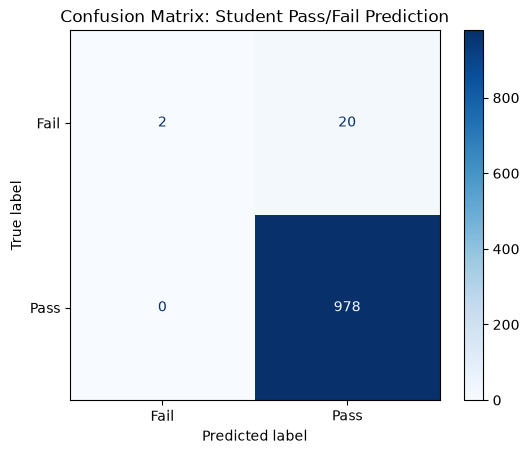

In [26]:
labels = model.named_steps["classifier"].classes_

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix: Student Pass/Fail Prediction")
plt.show()


## Conclusion

In this notebook, we developed a logistic regression model to
predict student pass/fail outcomes using available student
performance features.

We split the dataset into training and testing sets, preprocessed
the features, trained the classifier, and evaluated its performance
using accuracy, precision, recall, F1-score, and a confusion matrix.

The results help us understand how well the model classifies
unseen student records. The ROC curve and AUC, when applicable,
provide additional information about its ability to distinguish
between the two classes.

The model's performance should be interpreted alongside the
class distribution and the quality of the input data.
